In [3]:
# ============================================================
# ViT-B/16 — CELL 1
# Install + Imports + Configuration + Dataset Auto-Detection
# + Output Folders
# ============================================================

!pip -q install -U timm fvcore scipy statsmodels openpyxl

from google.colab import drive
drive.mount(
    "/content/drive",
    force_remount=False
)


# ============================================================
# 1. IMPORTS
# ============================================================

import os
import gc
import time
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms
from torchvision.transforms import InterpolationMode

import timm

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")


# ============================================================
# 2. SAME EXPERIMENTAL CONFIGURATION
# ============================================================

SEED = 42

IMG_SIZE = 224

BATCH_SIZE = 32

EPOCHS = 30

LEARNING_RATE = 1e-4

N_FOLDS = 5

THRESHOLD = 0.50

NUM_WORKERS = 2


# ============================================================
# 3. MODEL INFORMATION
# ============================================================

MODEL_NAME = "ViT-B/16"

TIMM_MODEL_NAME = (
    "vit_base_patch16_224.augreg_in21k_ft_in1k"
)

MODEL_FOLDER_NAME = (
    "06_ViT_B16"
)


# ============================================================
# 4. CLASS INFORMATION
# ============================================================

CLASS_NAMES = [
    "encroachment_present",
    "no_encroachment"
]

CLASS_TO_IDX = {
    "encroachment_present": 0,
    "no_encroachment": 1
}

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)


# ============================================================
# 5. DATASET SEARCH ROOT
# ============================================================

SEARCH_ROOT = Path(
    "/content/drive/MyDrive/Brishty_ml/"
    "clean_dataset_brishty"
)


if not SEARCH_ROOT.exists():

    raise FileNotFoundError(
        f"Dataset root was not found:\n"
        f"{SEARCH_ROOT}"
    )


# ============================================================
# 6. AUTO-DETECT ACTUAL CLASS-FOLDER DIRECTORY
# ============================================================

possible_dataset_directories = []


candidate_directories = [
    SEARCH_ROOT
]


candidate_directories.extend(
    [
        path
        for path in SEARCH_ROOT.rglob("*")
        if path.is_dir()
    ]
)


for candidate_directory in candidate_directories:

    has_all_classes = all(

        (
            candidate_directory /
            class_name
        ).is_dir()

        for class_name in CLASS_NAMES
    )


    if has_all_classes:

        possible_dataset_directories.append(
            candidate_directory
        )


if len(
    possible_dataset_directories
) == 0:

    raise FileNotFoundError(
        "Could not find a directory containing both:\n"
        "encroachment_present\n"
        "no_encroachment"
    )


DATASET_DIR = (
    possible_dataset_directories[0]
)


# ============================================================
# 7. OUTPUT ROOT
# ============================================================

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Brishty_ml/"
    "reviewer_final_results"
)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 8. MODEL-SPECIFIC OUTPUT FOLDERS
# ============================================================

MODEL_OUTPUT_DIR = (
    OUTPUT_DIR /
    MODEL_FOLDER_NAME
)

MODEL_DIR = (
    MODEL_OUTPUT_DIR /
    "saved_models"
)

HISTORY_DIR = (
    MODEL_OUTPUT_DIR /
    "training_history"
)

FIGURE_DIR = (
    MODEL_OUTPUT_DIR /
    "figures"
)

PREDICTION_DIR = (
    MODEL_OUTPUT_DIR /
    "predictions"
)

METRIC_DIR = (
    MODEL_OUTPUT_DIR /
    "metrics"
)


for folder in [
    MODEL_OUTPUT_DIR,
    MODEL_DIR,
    HISTORY_DIR,
    FIGURE_DIR,
    PREDICTION_DIR,
    METRIC_DIR
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 9. FIXED SPLIT PATHS
# ============================================================

COMPLETE_SPLIT_PATH = (
    OUTPUT_DIR /
    "fixed_test_and_5fold_split.csv"
)

FOLD_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_5fold_development_set.csv"
)

TEST_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)


# ============================================================
# 10. DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# 11. REPRODUCIBILITY
# ============================================================

def set_seed(
    seed=42
):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed(
    SEED
)


# ============================================================
# 12. COUNT IMAGES
# ============================================================

class_image_counts = {}


for class_name in CLASS_NAMES:

    class_folder = (
        DATASET_DIR /
        class_name
    )


    image_count = sum(

        1

        for file_path in
        class_folder.rglob("*")

        if (
            file_path.is_file()
            and
            file_path.suffix.lower()
            in IMAGE_EXTENSIONS
        )
    )


    class_image_counts[
        class_name
    ] = image_count


    if image_count == 0:

        raise RuntimeError(
            f"No images found inside:\n"
            f"{class_folder}"
        )


# ============================================================
# 13. FINAL CHECK
# ============================================================

print("=" * 75)
print("ViT-B/16 CELL 1 COMPLETED")
print("=" * 75)

print(
    "Device:",
    DEVICE
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


print(
    "\nModel:",
    MODEL_NAME
)

print(
    "Checkpoint:",
    TIMM_MODEL_NAME
)


print(
    "\nDataset search root:"
)

print(
    SEARCH_ROOT
)


print(
    "\nDetected dataset directory:"
)

print(
    DATASET_DIR
)


print(
    "\nDataset class counts:"
)


total_images = 0


for class_name, image_count in (
    class_image_counts.items()
):

    print(
        f"{class_name}: "
        f"{image_count}"
    )

    total_images += image_count


print(
    "Total images:",
    total_images
)


print(
    "\nImage size:",
    IMG_SIZE
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Epochs:",
    EPOCHS
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Number of folds:",
    N_FOLDS
)

print(
    "Number of workers:",
    NUM_WORKERS
)


print(
    "\nOutput folder:"
)

print(
    MODEL_OUTPUT_DIR
)


print(
    "\nNo fold has been trained yet."
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ViT-B/16 CELL 1 COMPLETED
Device: cuda
GPU: Tesla T4

Model: ViT-B/16
Checkpoint: vit_base_patch16_224.augreg_in21k_ft_in1k

Dataset search root:
/content/drive/MyDrive/Brishty_ml/clean_dataset_brishty

Detected dataset directory:
/content/drive/MyDrive/Brishty_ml/clean_dataset_brishty/images

Dataset class counts:
encroachment_present: 3891
no_encroachment: 3520
Total images: 7411

Image size: 224
Batch size: 32
Epochs: 30
Learning rate: 0.0001
Number of folds: 5
Number of workers: 2

Output folder:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16

No fold has been trained yet.


In [4]:
# ============================================================
# ViT-B/16 — CELL 2
# Fixed Split + Preprocessing + DataLoader
# ViT Model + Training/Evaluation Functions
# ============================================================


# ============================================================
# 1. COLLECT ALL IMAGES FROM DETECTED DATASET
# ============================================================

def collect_images(dataset_dir):

    image_paths = []
    labels = []

    for class_name in CLASS_NAMES:

        class_folder = (
            dataset_dir /
            class_name
        )

        for root, directories, files in os.walk(
            class_folder
        ):

            directories.sort()

            for file_name in sorted(files):

                if file_name.lower().endswith(
                    IMAGE_EXTENSIONS
                ):

                    image_path = str(
                        Path(root) /
                        file_name
                    )

                    image_paths.append(
                        image_path
                    )

                    labels.append(
                        CLASS_TO_IDX[
                            class_name
                        ]
                    )


    return (
        np.asarray(
            image_paths
        ),
        np.asarray(
            labels,
            dtype=np.int64
        )
    )


all_image_paths, all_labels = (
    collect_images(
        DATASET_DIR
    )
)


if len(all_image_paths) == 0:

    raise RuntimeError(
        f"No images found inside:\n"
        f"{DATASET_DIR}"
    )


print("=" * 75)
print("CLEANED DATASET SUMMARY")
print("=" * 75)

print(
    "Total images found:",
    len(all_image_paths)
)


for class_name, class_index in (
    CLASS_TO_IDX.items()
):

    class_count = int(
        np.sum(
            all_labels ==
            class_index
        )
    )

    print(
        f"{class_name}: "
        f"{class_count}"
    )


# ============================================================
# 2. CHECK WHETHER EXISTING FIXED SPLITS
#    BELONG TO CURRENT DATASET
# ============================================================

def fixed_splits_are_valid():

    if not (
        FOLD_CSV_PATH.exists()
        and
        TEST_CSV_PATH.exists()
    ):

        return False


    try:

        old_development_df = pd.read_csv(
            FOLD_CSV_PATH
        )

        old_test_df = pd.read_csv(
            TEST_CSV_PATH
        )

    except Exception:

        return False


    required_columns = {
        "image_path",
        "label",
        "class_name",
        "dataset_role",
        "fold_id"
    }


    if not required_columns.issubset(
        old_development_df.columns
    ):

        return False


    if not required_columns.issubset(
        old_test_df.columns
    ):

        return False


    old_paths = set(

        pd.concat(
            [
                old_development_df[
                    "image_path"
                ],

                old_test_df[
                    "image_path"
                ]
            ],
            ignore_index=True
        )
        .astype(str)
        .tolist()
    )


    current_paths = set(
        all_image_paths
        .astype(str)
        .tolist()
    )


    return (
        old_paths ==
        current_paths
    )


# ============================================================
# 3. LOAD EXISTING FIXED SPLIT OR CREATE SAME SPLIT
# ============================================================

if fixed_splits_are_valid():

    print(
        "\nMatching fixed split files found."
    )

    print(
        "Existing test set and 5 folds "
        "will be reused."
    )


    development_df = pd.read_csv(
        FOLD_CSV_PATH
    )

    test_df = pd.read_csv(
        TEST_CSV_PATH
    )


else:

    print(
        "\nMatching fixed split files "
        "were not found."
    )

    print(
        "Creating fixed 15% test set "
        "and stratified 5 folds."
    )


    # --------------------------------------------------------
    # Same 15% independent test set
    # --------------------------------------------------------

    (
        development_paths,
        test_paths,
        development_labels,
        test_labels
    ) = train_test_split(

        all_image_paths,
        all_labels,

        test_size=0.15,

        random_state=SEED,

        stratify=all_labels,

        shuffle=True
    )


    # --------------------------------------------------------
    # Same Stratified 5-Fold CV assignment
    # --------------------------------------------------------

    development_fold_ids = np.zeros(
        len(development_paths),
        dtype=np.int64
    )


    stratified_kfold = StratifiedKFold(

        n_splits=N_FOLDS,

        shuffle=True,

        random_state=SEED
    )


    for fold_number, (
        _,
        validation_indices
    ) in enumerate(

        stratified_kfold.split(
            development_paths,
            development_labels
        ),

        start=1
    ):

        development_fold_ids[
            validation_indices
        ] = fold_number


    if np.any(
        development_fold_ids == 0
    ):

        raise RuntimeError(
            "Some development images were "
            "not assigned to a fold."
        )


    development_df = pd.DataFrame({

        "image_path":
            development_paths,

        "label":
            development_labels.astype(int),

        "class_name": [
            CLASS_NAMES[
                int(label)
            ]
            for label in
            development_labels
        ],

        "dataset_role":
            "development",

        "fold_id":
            development_fold_ids
    })


    test_df = pd.DataFrame({

        "image_path":
            test_paths,

        "label":
            test_labels.astype(int),

        "class_name": [
            CLASS_NAMES[
                int(label)
            ]
            for label in
            test_labels
        ],

        "dataset_role":
            "test",

        "fold_id":
            0
    })


    complete_split_df = pd.concat(
        [
            development_df,
            test_df
        ],
        ignore_index=True
    )


    development_df.to_csv(
        FOLD_CSV_PATH,
        index=False
    )


    test_df.to_csv(
        TEST_CSV_PATH,
        index=False
    )


    complete_split_df.to_csv(
        COMPLETE_SPLIT_PATH,
        index=False
    )


    print(
        "Fixed split files created successfully."
    )


# ============================================================
# 4. STANDARDIZE TYPES
# ============================================================

development_df[
    "label"
] = development_df[
    "label"
].astype(int)


development_df[
    "fold_id"
] = development_df[
    "fold_id"
].astype(int)


test_df[
    "label"
] = test_df[
    "label"
].astype(int)


available_folds = sorted(
    development_df[
        "fold_id"
    ]
    .unique()
    .tolist()
)


if available_folds != [
    1,
    2,
    3,
    4,
    5
]:

    raise ValueError(
        f"Unexpected fold IDs: "
        f"{available_folds}"
    )


# ============================================================
# 5. VERIFY IMAGE PATHS
# ============================================================

missing_development = int(

    (
        ~development_df[
            "image_path"
        ].apply(
            lambda path:
                Path(path).exists()
        )
    ).sum()
)


missing_test = int(

    (
        ~test_df[
            "image_path"
        ].apply(
            lambda path:
                Path(path).exists()
        )
    ).sum()
)


if missing_development > 0:

    raise FileNotFoundError(
        f"{missing_development} "
        f"development images are missing."
    )


if missing_test > 0:

    raise FileNotFoundError(
        f"{missing_test} "
        f"test images are missing."
    )


print(
    "\nDevelopment images:",
    len(development_df)
)

print(
    "Independent test images:",
    len(test_df)
)

print(
    "Fold IDs:",
    available_folds
)


# ============================================================
# 6. SHOW FOLD DISTRIBUTION
# ============================================================

for fold_number in range(
    1,
    N_FOLDS + 1
):

    fold_train_df = development_df[
        development_df[
            "fold_id"
        ] != fold_number
    ]


    fold_validation_df = development_df[
        development_df[
            "fold_id"
        ] == fold_number
    ]


    print(
        f"\nFold {fold_number}"
    )

    print(
        "  Training images:",
        len(fold_train_df)
    )

    print(
        "  Validation images:",
        len(fold_validation_df)
    )


# ============================================================
# 7. IMAGENET NORMALIZATION
# ============================================================

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]


IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


# ============================================================
# 8. TRAINING AUGMENTATION
# Same comparison pipeline
# ============================================================

train_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomHorizontalFlip(
        p=0.50
    ),

    transforms.RandomRotation(
        degrees=36,
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomAffine(
        degrees=0,
        scale=(
            0.90,
            1.10
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 9. VALIDATION / TEST TRANSFORM
# ============================================================

evaluation_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ============================================================
# 10. DATASET CLASS
# ============================================================

class SEVDDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.transform = transform


    def __len__(
        self
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]


        image_path = str(
            row[
                "image_path"
            ]
        )


        label = float(
            row[
                "label"
            ]
        )


        try:

            with Image.open(
                image_path
            ) as opened_image:

                image = opened_image.convert(
                    "RGB"
                )


        except Exception as error:

            raise RuntimeError(
                f"Unable to load image:\n"
                f"{image_path}"
            ) from error


        if self.transform is not None:

            image = self.transform(
                image
            )


        return {

            "image":
                image,

            "label":
                torch.tensor(
                    label,
                    dtype=torch.float32
                ),

            "image_path":
                image_path
        }


# ============================================================
# 11. DATALOADER FUNCTION
# ============================================================

def create_dataloader(
    dataframe,
    transform,
    shuffle,
    fold_seed=SEED
):

    dataset = SEVDDataset(
        dataframe=dataframe,
        transform=transform
    )


    generator = torch.Generator()

    generator.manual_seed(
        fold_seed
    )


    dataloader = DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=shuffle,

        num_workers=NUM_WORKERS,

        pin_memory=(
            torch.cuda.is_available()
        ),

        persistent_workers=(
            NUM_WORKERS > 0
        ),

        drop_last=False,

        generator=(
            generator
            if shuffle
            else None
        )
    )


    return (
        dataset,
        dataloader
    )


# ============================================================
# 12. CREATE FIXED TEST LOADER
# ============================================================

test_dataset, test_loader = (
    create_dataloader(

        dataframe=test_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=SEED
    )
)


# ============================================================
# 13. ViT-B/16 MODEL
# ============================================================

class ViTB16BinaryClassifier(
    nn.Module
):

    def __init__(
        self,
        dropout_rate=0.4
    ):

        super().__init__()


        # ----------------------------------------------------
        # Pretrained ViT-B/16
        # Original classifier removed
        # ----------------------------------------------------

        self.backbone = timm.create_model(

            TIMM_MODEL_NAME,

            pretrained=True,

            num_classes=0,

            global_pool="token"
        )


        # ----------------------------------------------------
        # Freeze complete pretrained backbone
        # ----------------------------------------------------

        for parameter in (
            self.backbone.parameters()
        ):

            parameter.requires_grad = False


        self.feature_dimension = (
            self.backbone.num_features
        )


        # Same binary head policy

        self.dropout = nn.Dropout(
            p=dropout_rate
        )


        self.binary_output = nn.Linear(
            self.feature_dimension,
            1
        )


    def forward(
        self,
        images
    ):

        features = self.backbone(
            images
        )


        features = self.dropout(
            features
        )


        logits = self.binary_output(
            features
        )


        return logits.squeeze(
            dim=1
        )


# ============================================================
# 14. MODEL BUILDER
# ============================================================

def build_vit_b16_model():

    model = ViTB16BinaryClassifier(
        dropout_rate=0.4
    ).to(
        DEVICE
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.Adam(

        filter(
            lambda parameter:
                parameter.requires_grad,

            model.parameters()
        ),

        lr=LEARNING_RATE
    )


    return (
        model,
        criterion,
        optimizer
    )


# ============================================================
# 15. TRAIN ONE EPOCH
# ============================================================

def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    epoch_number
):

    model.train()


    # Keep frozen backbone in eval mode

    model.backbone.eval()


    running_loss = 0.0

    all_labels = []

    all_predictions = []


    progress_bar = tqdm(

        dataloader,

        desc=(
            f"Epoch {epoch_number:02d}/"
            f"{EPOCHS} Training"
        ),

        leave=False
    )


    for batch in progress_bar:

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )


        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        logits = model(
            images
        )


        loss = criterion(
            logits,
            labels
        )


        # Actual gradient calculation

        loss.backward()


        # Actual classification-head weight update

        optimizer.step()


        probabilities = torch.sigmoid(
            logits
        )


        predictions = (
            probabilities >=
            THRESHOLD
        ).long()


        batch_size = images.size(
            0
        )


        running_loss += (
            loss.item() *
            batch_size
        )


        all_labels.extend(

            labels
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        all_predictions.extend(

            predictions
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        progress_bar.set_postfix(
            loss=(
                f"{loss.item():.4f}"
            )
        )


    return {

        "loss":
            float(
                running_loss /
                len(
                    dataloader.dataset
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    all_labels,
                    all_predictions
                )
            )
    }


# ============================================================
# 16. EVALUATE MODEL
# ============================================================

def evaluate_model(
    model,
    dataloader,
    criterion,
    description="Validation"
):

    model.eval()


    running_loss = 0.0

    all_labels = []

    all_probabilities = []

    all_predictions = []

    all_image_paths = []


    progress_bar = tqdm(
        dataloader,
        desc=description,
        leave=False
    )


    with torch.no_grad():

        for batch in progress_bar:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )


            labels = batch[
                "label"
            ].to(
                DEVICE,
                non_blocking=True
            )


            logits = model(
                images
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = torch.sigmoid(
                logits
            )


            predictions = (
                probabilities >=
                THRESHOLD
            ).long()


            batch_size = images.size(
                0
            )


            running_loss += (
                loss.item() *
                batch_size
            )


            all_labels.extend(

                labels
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_probabilities.extend(

                probabilities
                .cpu()
                .numpy()
                .tolist()
            )


            all_predictions.extend(

                predictions
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_image_paths.extend(
                batch[
                    "image_path"
                ]
            )


    labels_array = np.asarray(
        all_labels,
        dtype=int
    )


    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float
    )


    predictions_array = np.asarray(
        all_predictions,
        dtype=int
    )


    confusion = confusion_matrix(
        labels_array,
        predictions_array,
        labels=[
            0,
            1
        ]
    )


    return {

        "loss":
            float(
                running_loss /
                len(
                    dataloader.dataset
                )
            ),

        "accuracy":
            float(
                accuracy_score(
                    labels_array,
                    predictions_array
                )
            ),

        "precision":
            float(
                precision_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "f1_score":
            float(
                f1_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "auc":
            float(
                roc_auc_score(
                    labels_array,
                    probabilities_array
                )
            ),

        "true_negative":
            int(
                confusion[
                    0,
                    0
                ]
            ),

        "false_positive":
            int(
                confusion[
                    0,
                    1
                ]
            ),

        "false_negative":
            int(
                confusion[
                    1,
                    0
                ]
            ),

        "true_positive":
            int(
                confusion[
                    1,
                    1
                ]
            ),

        "true_labels":
            labels_array,

        "probabilities":
            probabilities_array,

        "predictions":
            predictions_array,

        "image_paths":
            np.asarray(
                all_image_paths,
                dtype=str
            )
    }


# ============================================================
# 17. FOLD 1 SAFETY CHECK
# ============================================================

CHECK_FOLD = 1


check_train_df = development_df[
    development_df[
        "fold_id"
    ] != CHECK_FOLD
].reset_index(
    drop=True
)


check_validation_df = development_df[
    development_df[
        "fold_id"
    ] == CHECK_FOLD
].reset_index(
    drop=True
)


check_train_dataset, check_train_loader = (
    create_dataloader(

        dataframe=check_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            CHECK_FOLD
        )
    )
)


check_validation_dataset, check_validation_loader = (
    create_dataloader(

        dataframe=check_validation_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=(
            SEED +
            CHECK_FOLD
        )
    )
)


sample_batch = next(
    iter(
        check_train_loader
    )
)


# ============================================================
# 18. MODEL SAFETY CHECK
# ============================================================

verification_model, _, _ = (
    build_vit_b16_model()
)


verification_model.eval()


with torch.no_grad():

    dummy_output = verification_model(

        sample_batch[
            "image"
        ][:2].to(
            DEVICE
        )
    )


total_parameters = sum(
    parameter.numel()
    for parameter in
    verification_model.parameters()
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in
    verification_model.parameters()
    if parameter.requires_grad
)


frozen_parameters = (
    total_parameters -
    trainable_parameters
)


backbone_trainable_parameters = sum(
    parameter.numel()
    for parameter in
    verification_model.backbone.parameters()
    if parameter.requires_grad
)


assert sample_batch[
    "image"
].shape[
    1:
] == (
    3,
    IMG_SIZE,
    IMG_SIZE
)


assert dummy_output.shape == (
    2,
)


assert backbone_trainable_parameters == 0


assert trainable_parameters > 0


# ============================================================
# 19. CELL 2 COMPLETION OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 75
)

print(
    "ViT-B/16 CELL 2 COMPLETED"
)

print(
    "=" * 75
)


print(
    "Dataset:",
    DATASET_DIR
)


print(
    "Development images:",
    len(
        development_df
    )
)


print(
    "Independent test images:",
    len(
        test_df
    )
)


print(
    "Fold IDs:",
    available_folds
)


print(
    "Fold 1 training images:",
    len(
        check_train_dataset
    )
)


print(
    "Fold 1 validation images:",
    len(
        check_validation_dataset
    )
)


print(
    "Test images:",
    len(
        test_dataset
    )
)


print(
    "\nTraining batch shape:",
    sample_batch[
        "image"
    ].shape
)


print(
    "Model:",
    MODEL_NAME
)


print(
    "Checkpoint:",
    TIMM_MODEL_NAME
)


print(
    "Feature dimension:",
    verification_model.feature_dimension
)


print(
    "\nTotal parameters:",
    f"{total_parameters:,}"
)


print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)


print(
    "Frozen parameters:",
    f"{frozen_parameters:,}"
)


print(
    "Backbone frozen:",
    backbone_trainable_parameters == 0
)


print(
    "Dummy output shape:",
    dummy_output.shape
)


print(
    "\nOptimizer: Adam"
)


print(
    "Learning rate:",
    LEARNING_RATE
)


print(
    "Loss: BCEWithLogitsLoss"
)


print(
    "Dropout: 0.4"
)


print(
    "\nNo fold has been trained yet."
)


# ============================================================
# 20. CLEAN TEMPORARY OBJECTS
# ============================================================

del verification_model

del check_train_loader
del check_validation_loader

del check_train_dataset
del check_validation_dataset


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()

CLEANED DATASET SUMMARY
Total images found: 7411
encroachment_present: 3891
no_encroachment: 3520

Matching fixed split files were not found.
Creating fixed 15% test set and stratified 5 folds.
Fixed split files created successfully.

Development images: 6299
Independent test images: 1112
Fold IDs: [1, 2, 3, 4, 5]

Fold 1
  Training images: 5039
  Validation images: 1260

Fold 2
  Training images: 5039
  Validation images: 1260

Fold 3
  Training images: 5039
  Validation images: 1260

Fold 4
  Training images: 5039
  Validation images: 1260

Fold 5
  Training images: 5040
  Validation images: 1259


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            


ViT-B/16 CELL 2 COMPLETED
Dataset: /content/drive/MyDrive/Brishty_ml/clean_dataset_brishty/images
Development images: 6299
Independent test images: 1112
Fold IDs: [1, 2, 3, 4, 5]
Fold 1 training images: 5039
Fold 1 validation images: 1260
Test images: 1112

Training batch shape: torch.Size([32, 3, 224, 224])
Model: ViT-B/16
Checkpoint: vit_base_patch16_224.augreg_in21k_ft_in1k
Feature dimension: 768

Total parameters: 85,799,425
Trainable parameters: 769
Frozen parameters: 85,798,656
Backbone frozen: True
Dummy output shape: torch.Size([2])

Optimizer: Adam
Learning rate: 0.0001
Loss: BCEWithLogitsLoss
Dropout: 0.4

No fold has been trained yet.



STARTING ViT-B/16 FOLD 1/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2646
no_encroachment         2393
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present    661
no_encroachment         599
Name: count, dtype: int64


Epoch 01/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 01/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 1 | Epoch 01/30 - loss: 0.6204 - accuracy: 0.7164 - val_loss: 0.1816 - val_accuracy: 0.9452


Epoch 02/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 1 | Epoch 30/30 - loss: 0.0425 - accuracy: 0.9863 - val_loss: 0.0253 - val_accuracy: 0.9921

Fold 1 training time: 92.27 minutes


Fold 1 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 1 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

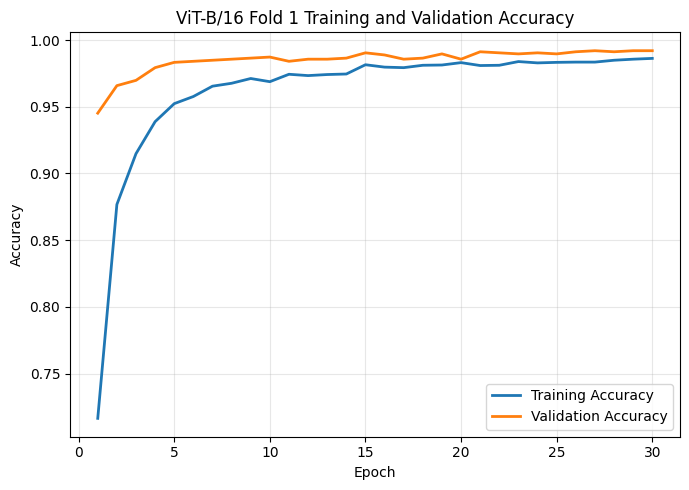

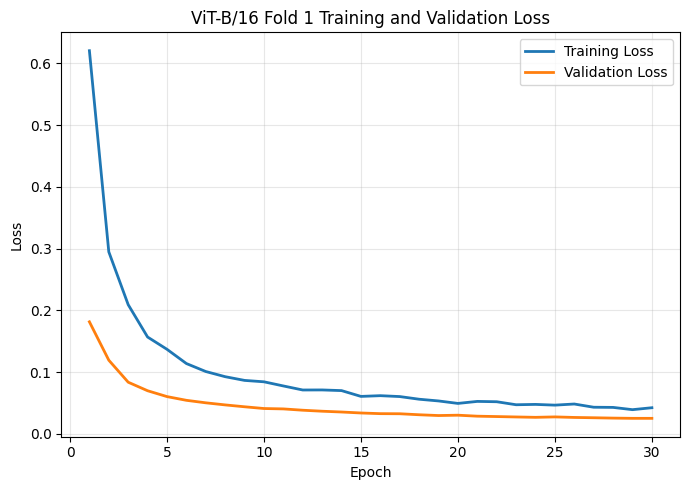


Validation Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,ViT-B/16,1,validation,0.025345,0.992063,0.994958,0.988314,0.991625,0.999631,658,3,7,592,5536.43429,92.273905



Independent Test Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,ViT-B/16,1,test,0.020812,0.995504,0.994329,0.996212,0.99527,0.999815,581,3,2,526,5536.43429,92.273905



Saved model:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/saved_models/ViT-B16_fold_1.pth

Saved history:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/training_history/ViT-B16_fold_1_history.csv

Saved validation predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_1_validation_predictions.csv

Saved test predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_1_test_predictions.csv

Saved fold summary:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/metrics/ViT-B16_fold_1_summary.csv

ViT-B/16 FOLD 1 COMPLETED

STARTING ViT-B/16 FOLD 2/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2646
no_encroachment         2393
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present    661
no_encroachme

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 2 | Epoch 30/30 - loss: 0.0434 - accuracy: 0.9849 - val_loss: 0.0209 - val_accuracy: 0.9921

Fold 2 training time: 79.49 minutes


Fold 2 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 2 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

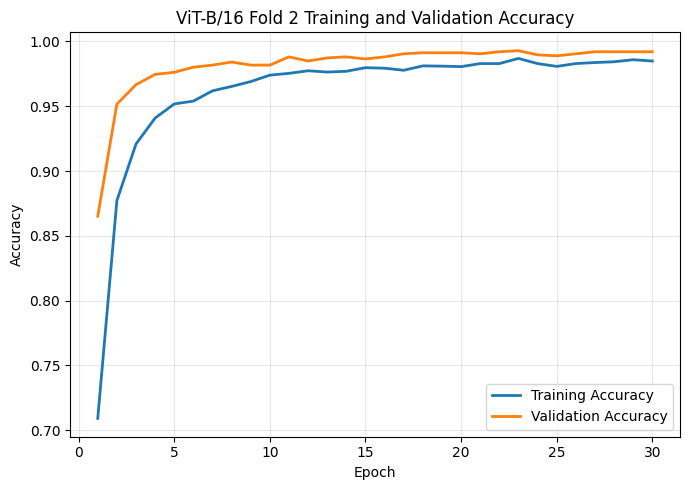

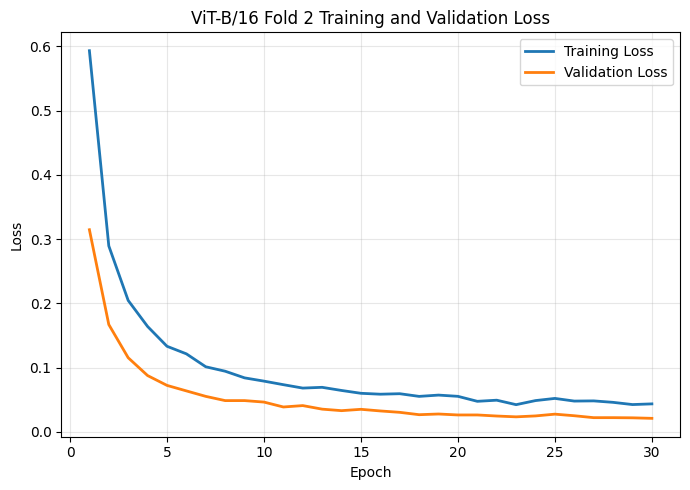


Validation Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,ViT-B/16,2,validation,0.020881,0.992063,0.996627,0.986644,0.991611,0.999922,659,2,8,591,4769.626829,79.49378



Independent Test Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,ViT-B/16,2,test,0.023553,0.991906,0.996176,0.986742,0.991437,0.999802,582,2,7,521,4769.626829,79.49378



Saved model:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/saved_models/ViT-B16_fold_2.pth

Saved history:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/training_history/ViT-B16_fold_2_history.csv

Saved validation predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_2_validation_predictions.csv

Saved test predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_2_test_predictions.csv

Saved fold summary:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/metrics/ViT-B16_fold_2_summary.csv

ViT-B/16 FOLD 2 COMPLETED

STARTING ViT-B/16 FOLD 3/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2645
no_encroachment         2394
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present    662
no_encroachme

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 3 | Epoch 30/30 - loss: 0.0427 - accuracy: 0.9855 - val_loss: 0.0282 - val_accuracy: 0.9897

Fold 3 training time: 80.45 minutes


Fold 3 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 3 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

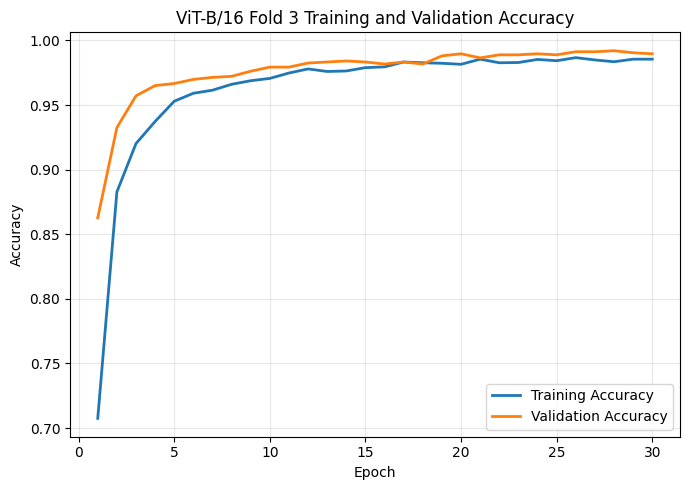

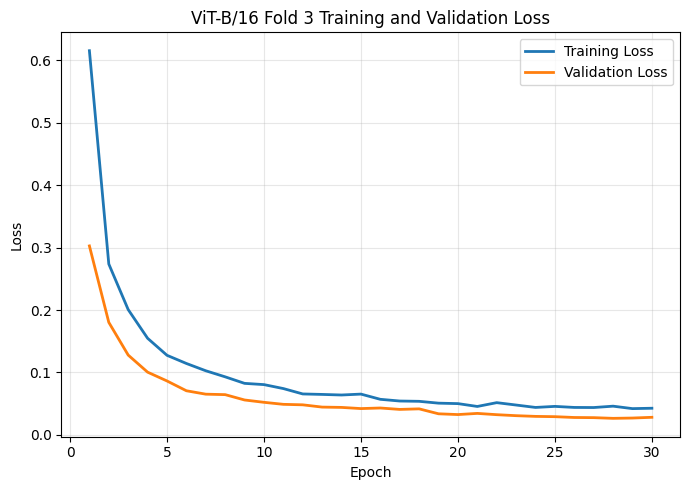


Validation Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,ViT-B/16,3,validation,0.028155,0.989683,0.996604,0.981605,0.989048,0.999689,660,2,11,587,4827.298959,80.454983



Independent Test Result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,ViT-B/16,3,test,0.024134,0.991906,0.998081,0.984848,0.99142,0.999799,583,1,8,520,4827.298959,80.454983



Saved model:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/saved_models/ViT-B16_fold_3.pth

Saved history:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/training_history/ViT-B16_fold_3_history.csv

Saved validation predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_3_validation_predictions.csv

Saved test predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/predictions/ViT-B16_fold_3_test_predictions.csv

Saved fold summary:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/06_ViT_B16/metrics/ViT-B16_fold_3_summary.csv

ViT-B/16 FOLD 3 COMPLETED

STARTING ViT-B/16 FOLD 4/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2645
no_encroachment         2394
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present    662
no_encroachme

...

Fold 4 | Epoch 27/30 - loss: 0.0499 - accuracy: 0.9821 - val_loss: 0.0173 - val_accuracy: 0.9968


Epoch 28/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 28/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 4 | Epoch 28/30 - loss: 0.0475 - accuracy: 0.9821 - val_loss: 0.0170 - val_accuracy: 0.9968


Epoch 29/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# ViT-B/16 — CELL 3
# ACTUAL 5-FOLD TRAINING + EVALUATION + SAVING
# ============================================================


# ============================================================
# 1. SAVE TRAINING HISTORY AND FOLD GRAPHS
# ============================================================

def save_history_and_graphs(
    history_dictionary,
    fold_number
):

    history_df = pd.DataFrame(
        history_dictionary
    )


    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )


    # --------------------------------------------------------
    # Save history CSV
    # --------------------------------------------------------

    history_path = (
        HISTORY_DIR /
        f"ViT-B16_fold_{fold_number}_history.csv"
    )


    history_df.to_csv(
        history_path,
        index=False
    )


    # --------------------------------------------------------
    # Accuracy curve
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 5)
    )


    plt.plot(
        history_df["epoch"],
        history_df["accuracy"],
        linewidth=2,
        label="Training Accuracy"
    )


    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"],
        linewidth=2,
        label="Validation Accuracy"
    )


    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Accuracy"
    )


    plt.title(
        f"ViT-B/16 Fold {fold_number} "
        f"Training and Validation Accuracy"
    )


    plt.legend()

    plt.grid(
        alpha=0.30
    )

    plt.tight_layout()


    accuracy_path = (
        FIGURE_DIR /
        f"ViT-B16_fold_{fold_number}_accuracy.png"
    )


    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    # --------------------------------------------------------
    # Loss curve
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 5)
    )


    plt.plot(
        history_df["epoch"],
        history_df["loss"],
        linewidth=2,
        label="Training Loss"
    )


    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        linewidth=2,
        label="Validation Loss"
    )


    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Loss"
    )


    plt.title(
        f"ViT-B/16 Fold {fold_number} "
        f"Training and Validation Loss"
    )


    plt.legend()

    plt.grid(
        alpha=0.30
    )

    plt.tight_layout()


    loss_path = (
        FIGURE_DIR /
        f"ViT-B16_fold_{fold_number}_loss.png"
    )


    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close()


    return {

        "history_dataframe":
            history_df,

        "history_path":
            history_path,

        "accuracy_path":
            accuracy_path,

        "loss_path":
            loss_path
    }


# ============================================================
# 2. SAVE VALIDATION / TEST PREDICTIONS
# ============================================================

def save_predictions(
    evaluation_result,
    fold_number,
    dataset_name
):

    prediction_df = pd.DataFrame({

        "image_path":
            evaluation_result[
                "image_paths"
            ],

        "label":
            evaluation_result[
                "true_labels"
            ],

        "class_name": [

            CLASS_NAMES[
                int(label)
            ]

            for label in
            evaluation_result[
                "true_labels"
            ]
        ],

        "predicted_probability_class_1":
            evaluation_result[
                "probabilities"
            ],

        "predicted_label":
            evaluation_result[
                "predictions"
            ],

        "predicted_class_name": [

            CLASS_NAMES[
                int(label)
            ]

            for label in
            evaluation_result[
                "predictions"
            ]
        ]
    })


    prediction_df[
        "correct_prediction"
    ] = (

        prediction_df[
            "label"
        ].astype(int)

        ==

        prediction_df[
            "predicted_label"
        ].astype(int)
    )


    prediction_path = (
        PREDICTION_DIR /
        f"ViT-B16_fold_{fold_number}_"
        f"{dataset_name}_predictions.csv"
    )


    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    return (
        prediction_df,
        prediction_path
    )


# ============================================================
# 3. SAVE MODEL CHECKPOINT
# ============================================================

def save_checkpoint(
    model,
    fold_number
):

    checkpoint_path = (
        MODEL_DIR /
        f"ViT-B16_fold_{fold_number}.pth"
    )


    checkpoint = {

        "model_name":
            MODEL_NAME,

        "timm_model_name":
            TIMM_MODEL_NAME,

        "fold":
            int(
                fold_number
            ),

        "image_size":
            IMG_SIZE,

        "batch_size":
            BATCH_SIZE,

        "epochs":
            EPOCHS,

        "learning_rate":
            LEARNING_RATE,

        "threshold":
            THRESHOLD,

        "class_names":
            CLASS_NAMES,

        "class_to_idx":
            CLASS_TO_IDX,

        "model_state_dict":
            model.state_dict()
    }


    torch.save(
        checkpoint,
        checkpoint_path
    )


    return checkpoint_path


# ============================================================
# 4. CREATE SUMMARY ROW
# ============================================================

def create_summary_row(
    evaluation_result,
    fold_number,
    dataset_name,
    training_time_seconds
):

    return {

        "model":
            MODEL_NAME,

        "fold":
            int(
                fold_number
            ),

        "dataset":
            dataset_name,

        "loss":
            float(
                evaluation_result[
                    "loss"
                ]
            ),

        "accuracy":
            float(
                evaluation_result[
                    "accuracy"
                ]
            ),

        "precision":
            float(
                evaluation_result[
                    "precision"
                ]
            ),

        "recall":
            float(
                evaluation_result[
                    "recall"
                ]
            ),

        "f1_score":
            float(
                evaluation_result[
                    "f1_score"
                ]
            ),

        "auc":
            float(
                evaluation_result[
                    "auc"
                ]
            ),

        "true_negative":
            int(
                evaluation_result[
                    "true_negative"
                ]
            ),

        "false_positive":
            int(
                evaluation_result[
                    "false_positive"
                ]
            ),

        "false_negative":
            int(
                evaluation_result[
                    "false_negative"
                ]
            ),

        "true_positive":
            int(
                evaluation_result[
                    "true_positive"
                ]
            ),

        "training_time_seconds":
            float(
                training_time_seconds
            ),

        "training_time_minutes":
            float(
                training_time_seconds /
                60
            )
    }


# ============================================================
# 5. ACTUAL FIVE-FOLD TRAINING
# ============================================================

all_summary_rows = []

completed_fold_results = {}


for fold_number in range(
    1,
    N_FOLDS + 1
):

    print(
        "\n" +
        "=" * 80
    )

    print(
        f"STARTING ViT-B/16 "
        f"FOLD {fold_number}/{N_FOLDS}"
    )

    print(
        "=" * 80
    )


    # --------------------------------------------------------
    # Fold-specific train / validation split
    # --------------------------------------------------------

    fold_train_df = (
        development_df[

            development_df[
                "fold_id"
            ] != fold_number
        ]

        .reset_index(
            drop=True
        )
    )


    fold_validation_df = (
        development_df[

            development_df[
                "fold_id"
            ] == fold_number
        ]

        .reset_index(
            drop=True
        )
    )


    print(
        "Training images:",
        len(
            fold_train_df
        )
    )


    print(
        "Validation images:",
        len(
            fold_validation_df
        )
    )


    print(
        "Independent test images:",
        len(
            test_df
        )
    )


    print(
        "\nTraining class distribution:"
    )


    print(
        fold_train_df[
            "class_name"
        ].value_counts()
    )


    print(
        "\nValidation class distribution:"
    )


    print(
        fold_validation_df[
            "class_name"
        ].value_counts()
    )


    # --------------------------------------------------------
    # Create DataLoaders
    # --------------------------------------------------------

    (
        fold_train_dataset,
        fold_train_loader
    ) = create_dataloader(

        dataframe=fold_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    (
        fold_validation_dataset,
        fold_validation_loader
    ) = create_dataloader(

        dataframe=fold_validation_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    # --------------------------------------------------------
    # Reproducibility for current fold
    # --------------------------------------------------------

    set_seed(
        SEED +
        fold_number
    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # BUILD FRESH ViT-B/16
    # --------------------------------------------------------

    model, criterion, optimizer = (
        build_vit_b16_model()
    )


    history_dictionary = {

        "loss":
            [],

        "accuracy":
            [],

        "val_loss":
            [],

        "val_accuracy":
            []
    }


    # --------------------------------------------------------
    # Start fold training timer
    # --------------------------------------------------------

    training_start_time = (
        time.perf_counter()
    )


    # ========================================================
    # ACTUAL 30-EPOCH TRAINING LOOP
    # ========================================================

    for epoch_number in range(
        1,
        EPOCHS + 1
    ):

        # ----------------------------------------------------
        # THIS CALL ACTUALLY TRAINS THE MODEL
        # train_one_epoch contains:
        #
        # loss.backward()
        # optimizer.step()
        # ----------------------------------------------------

        training_result = train_one_epoch(

            model=model,

            dataloader=fold_train_loader,

            criterion=criterion,

            optimizer=optimizer,

            epoch_number=epoch_number
        )


        # ----------------------------------------------------
        # Validation after current epoch
        # ----------------------------------------------------

        validation_result = evaluate_model(

            model=model,

            dataloader=fold_validation_loader,

            criterion=criterion,

            description=(
                f"Epoch {epoch_number:02d}/"
                f"{EPOCHS} Validation"
            )
        )


        # ----------------------------------------------------
        # Store epoch history
        # ----------------------------------------------------

        history_dictionary[
            "loss"
        ].append(
            training_result[
                "loss"
            ]
        )


        history_dictionary[
            "accuracy"
        ].append(
            training_result[
                "accuracy"
            ]
        )


        history_dictionary[
            "val_loss"
        ].append(
            validation_result[
                "loss"
            ]
        )


        history_dictionary[
            "val_accuracy"
        ].append(
            validation_result[
                "accuracy"
            ]
        )


        # ----------------------------------------------------
        # Epoch output
        # ----------------------------------------------------

        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch_number:02d}/{EPOCHS} - "
            f"loss: "
            f"{training_result['loss']:.4f} - "
            f"accuracy: "
            f"{training_result['accuracy']:.4f} - "
            f"val_loss: "
            f"{validation_result['loss']:.4f} - "
            f"val_accuracy: "
            f"{validation_result['accuracy']:.4f}"
        )


    # --------------------------------------------------------
    # End training timer
    # --------------------------------------------------------

    training_time_seconds = (

        time.perf_counter() -

        training_start_time
    )


    training_time_minutes = (

        training_time_seconds /

        60
    )


    print(
        f"\nFold {fold_number} "
        f"training time: "
        f"{training_time_minutes:.2f} minutes"
    )


    # ========================================================
    # FINAL VALIDATION EVALUATION
    # ========================================================

    final_validation_result = evaluate_model(

        model=model,

        dataloader=fold_validation_loader,

        criterion=criterion,

        description=(
            f"Fold {fold_number} "
            f"Final Validation"
        )
    )


    # ========================================================
    # INDEPENDENT TEST EVALUATION
    # ========================================================

    final_test_result = evaluate_model(

        model=model,

        dataloader=test_loader,

        criterion=criterion,

        description=(
            f"Fold {fold_number} "
            f"Independent Test"
        )
    )


    # ========================================================
    # SAVE HISTORY + GRAPHS
    # ========================================================

    history_outputs = (
        save_history_and_graphs(

            history_dictionary=(
                history_dictionary
            ),

            fold_number=fold_number
        )
    )


    # ========================================================
    # SAVE VALIDATION PREDICTIONS
    # ========================================================

    (
        validation_prediction_df,
        validation_prediction_path
    ) = save_predictions(

        evaluation_result=(
            final_validation_result
        ),

        fold_number=fold_number,

        dataset_name="validation"
    )


    # ========================================================
    # SAVE INDEPENDENT TEST PREDICTIONS
    # ========================================================

    (
        test_prediction_df,
        test_prediction_path
    ) = save_predictions(

        evaluation_result=(
            final_test_result
        ),

        fold_number=fold_number,

        dataset_name="test"
    )


    # ========================================================
    # SAVE MODEL
    # ========================================================

    checkpoint_path = save_checkpoint(

        model=model,

        fold_number=fold_number
    )


    # ========================================================
    # CREATE SUMMARY ROWS
    # ========================================================

    validation_summary = create_summary_row(

        evaluation_result=(
            final_validation_result
        ),

        fold_number=fold_number,

        dataset_name="validation",

        training_time_seconds=(
            training_time_seconds
        )
    )


    test_summary = create_summary_row(

        evaluation_result=(
            final_test_result
        ),

        fold_number=fold_number,

        dataset_name="test",

        training_time_seconds=(
            training_time_seconds
        )
    )


    fold_summary_df = pd.DataFrame([

        validation_summary,

        test_summary
    ])


    # ========================================================
    # SAVE CURRENT FOLD SUMMARY
    # ========================================================

    fold_summary_path = (
        METRIC_DIR /
        f"ViT-B16_fold_{fold_number}_summary.csv"
    )


    fold_summary_df.to_csv(
        fold_summary_path,
        index=False
    )


    all_summary_rows.extend([

        validation_summary,

        test_summary
    ])


    # ========================================================
    # KEEP CURRENT RUNTIME RESULTS
    # ========================================================

    completed_fold_results[
        fold_number
    ] = {

        "history":
            history_outputs[
                "history_dataframe"
            ],

        "validation_result":
            final_validation_result,

        "test_result":
            final_test_result,

        "summary":
            fold_summary_df,

        "checkpoint_path":
            checkpoint_path,

        "training_time_seconds":
            training_time_seconds
    }


    # ========================================================
    # SHOW CURRENT FOLD RESULTS
    # ========================================================

    print(
        "\nValidation Result:"
    )


    display(
        fold_summary_df[

            fold_summary_df[
                "dataset"
            ] == "validation"
        ]
    )


    print(
        "\nIndependent Test Result:"
    )


    display(
        fold_summary_df[

            fold_summary_df[
                "dataset"
            ] == "test"
        ]
    )


    print(
        "\nSaved model:"
    )

    print(
        checkpoint_path
    )


    print(
        "\nSaved history:"
    )

    print(
        history_outputs[
            "history_path"
        ]
    )


    print(
        "\nSaved validation predictions:"
    )

    print(
        validation_prediction_path
    )


    print(
        "\nSaved test predictions:"
    )

    print(
        test_prediction_path
    )


    print(
        "\nSaved fold summary:"
    )

    print(
        fold_summary_path
    )


    print(
        "\n" +
        "=" * 80
    )


    print(
        f"ViT-B/16 FOLD "
        f"{fold_number} COMPLETED"
    )


    print(
        "=" * 80
    )


    # ========================================================
    # CLEAN MEMORY BEFORE NEXT FOLD
    # ========================================================

    del model

    del criterion

    del optimizer

    del fold_train_loader

    del fold_validation_loader

    del fold_train_dataset

    del fold_validation_dataset


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# 6. SAVE COMPLETE 5-FOLD RESULTS
# ============================================================

all_folds_summary_df = pd.DataFrame(
    all_summary_rows
)


all_folds_summary_path = (
    METRIC_DIR /
    "ViT-B16_all_5fold_results.csv"
)


all_folds_summary_df.to_csv(
    all_folds_summary_path,
    index=False
)


# ============================================================
# 7. FINAL COMPLETION OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 80
)


print(
    "ViT-B/16 ALL FIVE FOLDS COMPLETED"
)


print(
    "=" * 80
)


print(
    "\nComplete five-fold result:"
)


print(
    all_folds_summary_path
)


print(
    "\nValidation Results:"
)


display(
    all_folds_summary_df[

        all_folds_summary_df[
            "dataset"
        ] == "validation"
    ]
)


print(
    "\nIndependent Test Results:"
)


display(
    all_folds_summary_df[

        all_folds_summary_df[
            "dataset"
        ] == "test"
    ]
)


print(
    "\nAll ViT-B/16 outputs saved inside:"
)


print(
    MODEL_OUTPUT_DIR
)

In [ ]:
# ============================================================
# ViT-B/16 — CELL 4
# FINAL POST-TRAINING PAPER-READY ANALYSIS
# Run after all 5 folds are completed
# ============================================================

from scipy import stats
from fvcore.nn import FlopCountAnalysis


# ============================================================
# 1. FINAL OUTPUT DIRECTORIES
# ============================================================

FINAL_RESULTS_DIR = (
    MODEL_OUTPUT_DIR /
    "final_standard_paper_results"
)

FINAL_TABLE_DIR = (
    FINAL_RESULTS_DIR /
    "tables"
)

FINAL_FIGURE_DIR = (
    FINAL_RESULTS_DIR /
    "figures"
)


FINAL_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 80)
print("ViT-B/16 FINAL POST-TRAINING ANALYSIS")
print("=" * 80)

print(
    "Final result folder:",
    FINAL_RESULTS_DIR
)


# ============================================================
# 2. VERIFY REQUIRED FILES
# ============================================================

def verify_required_file(
    file_path
):

    file_path = Path(
        file_path
    )

    if not file_path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n"
            f"{file_path}"
        )

    return file_path


for fold_number in range(
    1,
    N_FOLDS + 1
):

    verify_required_file(
        METRIC_DIR /
        f"ViT-B16_fold_{fold_number}_summary.csv"
    )

    verify_required_file(
        HISTORY_DIR /
        f"ViT-B16_fold_{fold_number}_history.csv"
    )

    verify_required_file(
        PREDICTION_DIR /
        f"ViT-B16_fold_{fold_number}_"
        f"validation_predictions.csv"
    )

    verify_required_file(
        MODEL_DIR /
        f"ViT-B16_fold_{fold_number}.pth"
    )


print(
    "All Fold 1–5 files found successfully."
)


# ============================================================
# 3. READ FIVE-FOLD VALIDATION RESULTS
# ============================================================

validation_rows = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    summary_path = (
        METRIC_DIR /
        f"ViT-B16_fold_{fold_number}_summary.csv"
    )


    fold_summary_df = pd.read_csv(
        summary_path
    )


    validation_df = fold_summary_df[

        fold_summary_df[
            "dataset"
        ]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq(
            "validation"
        )
    ]


    if len(
        validation_df
    ) != 1:

        raise ValueError(
            f"Fold {fold_number} must contain "
            f"exactly one validation row."
        )


    row = (
        validation_df
        .iloc[0]
        .to_dict()
    )


    row[
        "fold"
    ] = fold_number


    validation_rows.append(
        row
    )


validation_metrics_df = (
    pd.DataFrame(
        validation_rows
    )
    .sort_values(
        "fold"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nFive-fold validation results:"
)


display(
    validation_metrics_df[
        [
            "fold",
            "loss",
            "accuracy",
            "precision",
            "recall",
            "f1_score",
            "auc",
            "training_time_minutes"
        ]
    ]
)


# ============================================================
# 4. MEAN ± STANDARD DEVIATION
# ============================================================

metric_mapping = {

    "Loss":
        "loss",

    "Accuracy (%)":
        "accuracy",

    "Precision (%)":
        "precision",

    "Recall (%)":
        "recall",

    "F1-Score (%)":
        "f1_score",

    "AUC":
        "auc"
}


performance_record = {

    "Model":
        MODEL_NAME
}


for display_name, column_name in (
    metric_mapping.items()
):

    values = (
        validation_metrics_df[
            column_name
        ]
        .astype(float)
        .values
    )


    if display_name in [

        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"

    ]:

        values = (
            values *
            100
        )


    mean_value = float(
        np.mean(
            values
        )
    )


    standard_deviation = float(
        np.std(
            values,
            ddof=1
        )
    )


    performance_record[
        display_name
    ] = (
        f"{mean_value:.2f} ± "
        f"{standard_deviation:.2f}"
    )


performance_table_df = pd.DataFrame([
    performance_record
])


performance_table_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_performance_mean_std.csv"
)


performance_table_df.to_csv(
    performance_table_path,
    index=False
)


print(
    "\nPerformance Mean ± SD:"
)


display(
    performance_table_df
)


# ============================================================
# 5. ACCURACY 95% CONFIDENCE INTERVAL
# ============================================================

accuracy_values = (

    validation_metrics_df[
        "accuracy"
    ]
    .astype(float)
    .values *

    100
)


mean_accuracy = float(
    np.mean(
        accuracy_values
    )
)


accuracy_sd = float(
    np.std(
        accuracy_values,
        ddof=1
    )
)


accuracy_se = (

    accuracy_sd /

    np.sqrt(
        N_FOLDS
    )
)


t_critical = stats.t.ppf(

    0.975,

    df=(
        N_FOLDS -
        1
    )
)


confidence_margin = (

    t_critical *

    accuracy_se
)


ci_lower = (

    mean_accuracy -

    confidence_margin
)


ci_upper = (

    mean_accuracy +

    confidence_margin
)


confidence_interval_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Accuracy (%)":
            mean_accuracy,

        "Standard Deviation (%)":
            accuracy_sd,

        "Standard Error (%)":
            accuracy_se,

        "95% CI Lower (%)":
            ci_lower,

        "95% CI Upper (%)":
            ci_upper,

        "Paper Format":
            (
                f"{mean_accuracy:.2f}% "
                f"({ci_lower:.2f}%–"
                f"{ci_upper:.2f}%)"
            )
    }
])


confidence_interval_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_statistical_95CI.csv"
)


confidence_interval_df.to_csv(
    confidence_interval_path,
    index=False
)


print(
    "\nAccuracy 95% Confidence Interval:"
)


display(
    confidence_interval_df
)


# ============================================================
# 6. TRAINING TIME MEAN ± SD
# ============================================================

training_time_values = (

    validation_metrics_df[
        "training_time_minutes"
    ]
    .astype(float)
    .values
)


mean_training_time = float(
    np.mean(
        training_time_values
    )
)


training_time_sd = float(
    np.std(
        training_time_values,
        ddof=1
    )
)


training_time_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Training Time (minutes)":
            mean_training_time,

        "Training Time SD (minutes)":
            training_time_sd,

        "Mean ± SD":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_sd:.2f}"
            )
    }
])


training_time_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_training_time_mean_std.csv"
)


training_time_df.to_csv(
    training_time_path,
    index=False
)


print(
    "\nTraining Time Mean ± SD:"
)


display(
    training_time_df
)


# ============================================================
# 7. READ ALL FIVE TRAINING HISTORIES
# ============================================================

training_accuracy_list = []

validation_accuracy_list = []

training_loss_list = []

validation_loss_list = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    history_path = (
        HISTORY_DIR /
        f"ViT-B16_fold_{fold_number}_history.csv"
    )


    history_df = pd.read_csv(
        history_path
    )


    required_columns = {

        "epoch",
        "loss",
        "accuracy",
        "val_loss",
        "val_accuracy"
    }


    if not required_columns.issubset(
        history_df.columns
    ):

        raise KeyError(
            f"Fold {fold_number} history "
            f"is missing required columns."
        )


    training_accuracy_list.append(

        history_df[
            "accuracy"
        ]
        .astype(float)
        .values
    )


    validation_accuracy_list.append(

        history_df[
            "val_accuracy"
        ]
        .astype(float)
        .values
    )


    training_loss_list.append(

        history_df[
            "loss"
        ]
        .astype(float)
        .values
    )


    validation_loss_list.append(

        history_df[
            "val_loss"
        ]
        .astype(float)
        .values
    )


training_accuracy_matrix = np.vstack(
    training_accuracy_list
)


validation_accuracy_matrix = np.vstack(
    validation_accuracy_list
)


training_loss_matrix = np.vstack(
    training_loss_list
)


validation_loss_matrix = np.vstack(
    validation_loss_list
)


number_of_epochs = (
    training_accuracy_matrix.shape[
        1
    ]
)


epochs_array = np.arange(
    1,
    number_of_epochs + 1
)


# ============================================================
# 8. FIVE-FOLD MEAN ACCURACY CURVES
# ============================================================

mean_training_accuracy = np.mean(
    training_accuracy_matrix,
    axis=0
)


mean_validation_accuracy = np.mean(
    validation_accuracy_matrix,
    axis=0
)


plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        training_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        label=(
            f"Fold {fold_index + 1} Train"
        )
    )


    plt.plot(
        epochs_array,
        validation_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--",
        label=(
            f"Fold {fold_index + 1} Validation"
        )
    )


plt.plot(
    epochs_array,
    mean_training_accuracy,
    linewidth=3,
    label="Mean Training Accuracy"
)


plt.plot(
    epochs_array,
    mean_validation_accuracy,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Accuracy"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "ViT-B/16 5-Fold Training and Validation Accuracy"
)

plt.legend(
    fontsize=8,
    ncol=2
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


accuracy_curve_path = (
    FINAL_FIGURE_DIR /
    "ViT-B16_5fold_mean_accuracy_curves.png"
)


plt.savefig(
    accuracy_curve_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 9. FIVE-FOLD MEAN LOSS CURVES
# ============================================================

mean_training_loss = np.mean(
    training_loss_matrix,
    axis=0
)


mean_validation_loss = np.mean(
    validation_loss_matrix,
    axis=0
)


plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        training_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        label=(
            f"Fold {fold_index + 1} Train"
        )
    )


    plt.plot(
        epochs_array,
        validation_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--",
        label=(
            f"Fold {fold_index + 1} Validation"
        )
    )


plt.plot(
    epochs_array,
    mean_training_loss,
    linewidth=3,
    label="Mean Training Loss"
)


plt.plot(
    epochs_array,
    mean_validation_loss,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "ViT-B/16 5-Fold Training and Validation Loss"
)

plt.legend(
    fontsize=8,
    ncol=2
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


loss_curve_path = (
    FINAL_FIGURE_DIR /
    "ViT-B16_5fold_mean_loss_curves.png"
)


plt.savefig(
    loss_curve_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 10. FIVE-FOLD ROC CURVES + MEAN ROC
# ============================================================

mean_fpr = np.linspace(
    0,
    1,
    1000
)


interpolated_tprs = []

fold_auc_values = []


plt.figure(
    figsize=(8, 6)
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"ViT-B16_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    true_labels = (
        prediction_df[
            "label"
        ]
        .astype(int)
        .values
    )


    probabilities = (
        prediction_df[
            "predicted_probability_class_1"
        ]
        .astype(float)
        .values
    )


    (
        fpr,
        tpr,
        _
    ) = roc_curve(
        true_labels,
        probabilities
    )


    fold_auc = roc_auc_score(
        true_labels,
        probabilities
    )


    fold_auc_values.append(
        fold_auc
    )


    interpolated_tpr = np.interp(
        mean_fpr,
        fpr,
        tpr
    )


    interpolated_tpr[
        0
    ] = 0.0


    interpolated_tprs.append(
        interpolated_tpr
    )


    plt.plot(
        fpr,
        tpr,
        alpha=0.50,
        linewidth=1.5,
        label=(
            f"Fold {fold_number} "
            f"(AUC={fold_auc:.4f})"
        )
    )


mean_tpr = np.mean(
    interpolated_tprs,
    axis=0
)


mean_tpr[
    0
] = 0.0


mean_tpr[
    -1
] = 1.0


mean_auc = float(
    np.mean(
        fold_auc_values
    )
)


auc_sd = float(
    np.std(
        fold_auc_values,
        ddof=1
    )
)


plt.plot(
    mean_fpr,
    mean_tpr,
    linewidth=3,
    label=(
        f"Mean ROC "
        f"(AUC={mean_auc:.4f} ± "
        f"{auc_sd:.4f})"
    )
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ViT-B/16 5-Fold Mean ROC Curve"
)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


roc_curve_path = (
    FINAL_FIGURE_DIR /
    "ViT-B16_5fold_mean_ROC_curve.png"
)


plt.savefig(
    roc_curve_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 11. SAVE ROC/AUC SUMMARY TABLE
# ============================================================

roc_auc_summary_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean AUC":
            mean_auc,

        "AUC SD":
            auc_sd,

        "Mean ± SD":
            (
                f"{mean_auc:.4f} ± "
                f"{auc_sd:.4f}"
            )
    }
])


roc_auc_summary_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_ROC_AUC_summary.csv"
)


roc_auc_summary_df.to_csv(
    roc_auc_summary_path,
    index=False
)


# ============================================================
# 12. COMBINED FIVE-FOLD CONFUSION MATRIX
# ============================================================

combined_confusion_matrix = np.zeros(
    (
        2,
        2
    ),
    dtype=int
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"ViT-B16_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    true_labels = (
        prediction_df[
            "label"
        ]
        .astype(int)
        .values
    )


    predicted_labels = (
        prediction_df[
            "predicted_label"
        ]
        .astype(int)
        .values
    )


    fold_cm = confusion_matrix(

        true_labels,

        predicted_labels,

        labels=[
            0,
            1
        ]
    )


    combined_confusion_matrix += (
        fold_cm
    )


plt.figure(
    figsize=(7, 6)
)


plt.imshow(
    combined_confusion_matrix,
    interpolation="nearest",
    cmap="Blues"
)


plt.colorbar()


display_class_names = [
    "Encroachment\nPresent",
    "No\nEncroachment"
]


plt.xticks(
    [0, 1],
    display_class_names
)


plt.yticks(
    [0, 1],
    display_class_names
)


matrix_threshold = (
    combined_confusion_matrix.max() /
    2.0
)


for row_index in range(
    2
):

    for column_index in range(
        2
    ):

        value = int(
            combined_confusion_matrix[
                row_index,
                column_index
            ]
        )


        plt.text(
            column_index,
            row_index,
            str(value),
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=15,
            color=(
                "white"
                if value >
                matrix_threshold
                else "black"
            )
        )


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "ViT-B/16 Combined 5-Fold Confusion Matrix"
)

plt.tight_layout()


confusion_matrix_path = (
    FINAL_FIGURE_DIR /
    "ViT-B16_combined_5fold_confusion_matrix.png"
)


plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

plt.close()


# ============================================================
# 13. SAVE CONFUSION MATRIX VALUES
# ============================================================

confusion_values_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "True Negative":
            int(
                combined_confusion_matrix[
                    0,
                    0
                ]
            ),

        "False Positive":
            int(
                combined_confusion_matrix[
                    0,
                    1
                ]
            ),

        "False Negative":
            int(
                combined_confusion_matrix[
                    1,
                    0
                ]
            ),

        "True Positive":
            int(
                combined_confusion_matrix[
                    1,
                    1
                ]
            )
    }
])


confusion_values_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_combined_confusion_matrix_values.csv"
)


confusion_values_df.to_csv(
    confusion_values_path,
    index=False
)


# ============================================================
# 14. LOAD FOLD 1 MODEL FOR COMPLEXITY ANALYSIS
# ============================================================

complexity_model, _, _ = (
    build_vit_b16_model()
)


fold_1_checkpoint_path = (
    MODEL_DIR /
    "ViT-B16_fold_1.pth"
)


fold_1_checkpoint = torch.load(
    fold_1_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)


complexity_model.load_state_dict(
    fold_1_checkpoint[
        "model_state_dict"
    ]
)


complexity_model = complexity_model.to(
    DEVICE
)


complexity_model.eval()


# ============================================================
# 15. PARAMETER COUNT
# ============================================================

total_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
    if parameter.requires_grad
)


non_trainable_parameters = (
    total_parameters -
    trainable_parameters
)


# ============================================================
# 16. MODEL CHECKPOINT SIZE
# ============================================================

model_size_mb = (

    fold_1_checkpoint_path
    .stat()
    .st_size /

    (1024 ** 2)
)


# ============================================================
# 17. GFLOPs
# ============================================================

try:

    dummy_input = torch.zeros(

        (
            1,
            3,
            IMG_SIZE,
            IMG_SIZE
        ),

        dtype=torch.float32,

        device=DEVICE
    )


    flop_analysis = FlopCountAnalysis(
        complexity_model,
        dummy_input
    )


    total_flops = float(
        flop_analysis.total()
    )


    gflops = (
        total_flops /
        1e9
    )


except Exception as error:

    print(
        "\nGFLOPs calculation warning:"
    )

    print(
        error
    )

    gflops = np.nan


# ============================================================
# 18. INFERENCE TIME + FPS
# ============================================================

# Warm-up

with torch.no_grad():

    for batch_index, batch in enumerate(
        test_loader
    ):

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )


        _ = complexity_model(
            images
        )


        if batch_index >= 4:

            break


if torch.cuda.is_available():

    torch.cuda.synchronize()


inference_trial_times = []


for trial_number in range(
    5
):

    start_time = (
        time.perf_counter()
    )


    with torch.no_grad():

        for batch in test_loader:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )


            _ = complexity_model(
                images
            )


    if torch.cuda.is_available():

        torch.cuda.synchronize()


    inference_trial_times.append(

        time.perf_counter() -

        start_time
    )


mean_inference_seconds = float(
    np.mean(
        inference_trial_times
    )
)


inference_ms_per_image = (

    mean_inference_seconds /

    len(
        test_dataset
    ) *

    1000
)


fps = (

    len(
        test_dataset
    ) /

    mean_inference_seconds
)


# ============================================================
# 19. COMPUTATIONAL COMPLEXITY TABLE
# ============================================================

complexity_table_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Parameters (M)":
            total_parameters /
            1e6,

        "Trainable Parameters (M)":
            trainable_parameters /
            1e6,

        "Non-trainable Parameters (M)":
            non_trainable_parameters /
            1e6,

        "GFLOPs":
            gflops,

        "Model Size (MB)":
            model_size_mb,

        "Inference Time (ms/image)":
            inference_ms_per_image,

        "FPS":
            fps,

        "Training Time (minutes)":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_sd:.2f}"
            )
    }
])


complexity_table_path = (
    FINAL_TABLE_DIR /
    "ViT-B16_computational_complexity.csv"
)


complexity_table_df.to_csv(
    complexity_table_path,
    index=False
)


print(
    "\nComputational Complexity:"
)


display(
    complexity_table_df
)


# ============================================================
# 20. CLEAN MEMORY
# ============================================================

del complexity_model


gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ============================================================
# 21. FINAL OUTPUT
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "ViT-B/16 FINAL ANALYSIS COMPLETED"
)

print(
    "=" * 80
)


print(
    "\nTABLES"
)


print(
    "1. Performance Mean ± SD:"
)

print(
    performance_table_path
)


print(
    "\n2. Accuracy 95% CI:"
)

print(
    confidence_interval_path
)


print(
    "\n3. Training Time Mean ± SD:"
)

print(
    training_time_path
)


print(
    "\n4. ROC/AUC Summary:"
)

print(
    roc_auc_summary_path
)


print(
    "\n5. Combined Confusion Matrix Values:"
)

print(
    confusion_values_path
)


print(
    "\n6. Computational Complexity:"
)

print(
    complexity_table_path
)


print(
    "\nFIGURES"
)


print(
    "7. Mean Accuracy Curves:"
)

print(
    accuracy_curve_path
)


print(
    "\n8. Mean Loss Curves:"
)

print(
    loss_curve_path
)


print(
    "\n9. Mean ROC Curve:"
)

print(
    roc_curve_path
)


print(
    "\n10. Combined Confusion Matrix:"
)

print(
    confusion_matrix_path
)


print(
    "\nAll final ViT-B/16 results saved inside:"
)

print(
    FINAL_RESULTS_DIR
)


print(
    "\nMcNemar test should be performed later "
    "between the final comparison models."
)


print(
    "Grad-CAM / Grad-CAM++ should be performed "
    "later only for the selected best/proposed model."
)